# 2. ROUGHNECK CRUDE OIL - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK
This notebook checks, **on in-sample data only**, that the configured rules sit on a broad, stable plateau of the parameter space and not on a lucky isolated peak. The out-of-sample block is never touched here.

### STRICT METHODOLOGICAL CONSTRAINT
Nothing is tuned to the data. The configured point comes from the published rules (LeBeau / Elden); the grid only asks *how fragile it is*. If the plateau gate fails, we document it and carry it to notebook 03 with the frozen parameters: we do not re-tune on this result.

### OBJECTIVES
1. 2D grid on the two parameters that define the long trigger: `long_atr_mult` x `atr_len`.
2. The same grid with costs x2 and x3 (the broker's spread and swap decide whether this edge exists).
3. Plateau + anti-cliff gate (`validation_gate.plateau_check`).
4. One-at-a-time sensitivity of the other rules (short trigger, stop, trend slope, entry window).
5. Dose-response of the trigger multiple and ATR method (simple vs Wilder).
6. Ablation by regime: trend filter, each exit component and sides.

### EDGE-SPECIFIC CHECKS (they matter more than the generic ones)
- The $1 stop and the 0.25 trend slope are in **price units**: they scale with the oil price level, so a plateau in the stop is as important as a plateau in the ATR multiple.
- Few trades per year (about 6-10): a single trade moves a cell's PF, so the sample-size gate is scaled to the in-sample length.

### STRATEGY PARAMETERS

In [5]:
VARIANT = "v1_axi_usoil"  # only base variants here; see variants/*.yaml
SCALE_SAMPLE_GATES = True   # short history: scale validation_gate plateau_n_min to the in-sample length (printed in section 2)

## 1. IMPORTS AND CONFIG

In [6]:
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')                  # edge folder (notebooks, engine and variants/ live together)
utils_path = str(find_upwards('utils') / 'utils')      # research_development/utils
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
from robustness import monte_carlo_block, monkey_test, grid_search, plateau_check, plot_grid, plot_monkey, profit_factor
from edge_decay import rolling_pf, plot_rolling_pf, pf_by_year, edge_decay_summary
from validation_gate import run_validation, DEFAULTS as GATE
import roughneck_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
COST_BPS   = P["cost_bps_per_side"]
SIZE_FRAC  = eng.ENGINE_DEFAULTS["size_fraction"]
CONTRACT_SIZE, MIN_LOT, LOT_STEP = (eng.ENGINE_DEFAULTS[k] for k in ("contract_size", "min_lot", "lot_step"))
PPY        = 252    # daily bars, futures-like calendar: annualisation for Sharpe
MULTS      = [float(x) for x in cfg["grid"]["long_atr_mult_values"]]
ATR_LENS   = [int(x) for x in cfg["grid"]["atr_len_values"]]
CHOSEN     = (float(P["long_atr_mult"]), int(P["atr_len"]))

# Frozen rules, passed as-is to every backtest call. Indicator rules go to prepare(), the rest to the backtest.
RULES = dict(P)
IND   = {k: RULES[k] for k in eng.IND_KEYS}
def prep(df_raw, **over):
    """prepare() with the frozen indicator rules, optionally overriding some (e.g. atr_len, trend_mode)."""
    return eng.prepare(df_raw, **{**IND, **over})

# Rules that never change in this notebook (long_atr_mult / atr_len are swept)
RULES_KW = {k: v for k, v in RULES.items() if k not in ("long_atr_mult", "atr_len")}

# ---- Style and helpers ----
BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRIDC, alpha=0.8)
    ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

# Oil regimes (an edge that only lives in one regime is a different edge): only the ones present in the data are used
ERAS_ALL = {"Pre-COVID (<=2019)": (1990, 2019), "COVID (2020)": (2020, 2020), "Post-COVID (2021+)": (2021, 2100)}
def era_of(y):
    return next(k for k, (a, b) in ERAS_ALL.items() if a <= y <= b)

def tstat(x):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def summarize(t):
    """PF / mean net % / t-stat / win rate of a trades frame (100% capital, net of costs)."""
    if len(t) == 0:
        return dict(n=0, pf=np.nan, mean=np.nan, t=np.nan, win=np.nan)
    return dict(n=len(t), pf=profit_factor(t["pnl"]), mean=float(t["pnl"].mean()), t=tstat(t["pnl"]), win=float((t["pnl"] > 0).mean() * 100))

print("Imports complete.")
print(f"Loaded roughneck_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | long: trend + close > LL({P['long_low_n']}) + {P['long_atr_mult']:g} ATR({P['atr_len']}) | "
      f"short: close < HH({P['short_high_n']}) - {P['short_atr_mult']:g} ATR | stop ${P['stop_dollar']:g} | {COST_BPS:g} bps/side | size {SIZE_FRAC:.0%}")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night | ATR method: {P['atr_method']}")
print(f"Run folder: {RUN_DIR}")
print(f"Grid: {len(MULTS)} long_atr_mult x {len(ATR_LENS)} ATR lengths = {len(MULTS) * len(ATR_LENS)} cells | candidate {CHOSEN}")
print(f"Gate criteria (validation_gate.DEFAULTS): PF >= {GATE['plateau_pf_min']}, N >= {GATE['plateau_n_min']}, max drop {GATE['plateau_max_drop']}%")

Imports complete.
Loaded roughneck_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/roughneck_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude
Variant: ROUGHNECK.usoil.cfd.v1 | usoil | long: trend + close > LL(8) + 1.5 ATR(45) | short: close < HH(3) - 2 ATR | stop $1 | 4 bps/side | size 100%
Data source: csv_h1 | swap: 1.5 bps/night | ATR method: sma
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_usoil
Grid: 7 long_atr_mult x 5 ATR lengths = 35 cells | candidate (1.5, 45)
Gate criteria (validation_gate.DEFAULTS): PF >= 1.3, N >= 30, max drop 30%


## 2. IN-SAMPLE DATA SETUP

In [7]:
df_raw = eng.load_data(TICKER, start=DATA_START)
_first_ok = lambda d: d.index[d["warm"].to_numpy().argmax()]
common_start = max(_first_ok(prep(df_raw, atr_len=L)) for L in ATR_LENS)

_cache = {}
def is_df(m, L):
    """In-sample slice of the indicators for (long_atr_mult=m, atr_len=L). Indicators use the full history (warm-up kept)."""
    if (m, L) not in _cache:
        d = prep(df_raw, atr_len=L, long_atr_mult=m)
        _cache[(m, L)] = d[(d.index >= common_start) & (d.index < OOS_START)]
    return _cache[(m, L)]

d0 = is_df(*CHOSEN)
assert len(d0) > 0, "Check oos_start_ts against the history."

GATE_ORIG = dict(GATE)
_is_years = (d0.index[-1] - d0.index[0]).days / 365.25
BASE_IS_YEARS = 6.5   # years of in-sample behind validation_gate.DEFAULTS
if SCALE_SAMPLE_GATES and _is_years < BASE_IS_YEARS:
    GATE['plateau_n_min'] = max(5, int(round(GATE_ORIG['plateau_n_min'] * _is_years / BASE_IS_YEARS)))
print(f"In-sample with warm-up done: {_is_years:.1f} years | plateau_n_min: {GATE_ORIG['plateau_n_min']} -> {GATE['plateau_n_min']}")
print('validation_gate.DEFAULTS in use:', GATE)
print("=" * 70)
print("IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)")
print("=" * 70)
print(f"Strict In-Sample Range: {d0.index.min():%Y-%m-%d} to {d0.index.max():%Y-%m-%d}")
print(f"Total In-Sample Bars: {len(d0):,}")
print(f"OOS block (not used here) starts: {pd.Timestamp(OOS_START):%Y-%m-%d}")

In-sample with warm-up done: 12.2 years | plateau_n_min: 30 -> 30
validation_gate.DEFAULTS in use: {'n_min': 30, 'pf_min': 1.3, 'mdd_min': -0.2, 'block': 5, 'mc_ret_p5_min': 0.0, 'mc_mdd_p5_min': -0.25, 'mc_ruin_max': 0.05, 'monkey_pct_min': 0.95, 'plateau_pf_min': 1.3, 'plateau_n_min': 30, 'plateau_max_drop': 30}
IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)
Strict In-Sample Range: 2010-09-30 to 2022-12-30
Total In-Sample Bars: 3,136
OOS block (not used here) starts: 2023-01-02


## 3. 2D PARAMETER GRID (LONG TRIGGER MULTIPLE x ATR LENGTH)

IN-SAMPLE PROFIT FACTOR GRID (rows = long_atr_mult, columns = ATR length)


,30,38,45,52,60
1.00,0.734,0.681,0.684,0.683,0.667
1.25,0.739,0.652,0.677,0.727,0.642
1.50,0.779,0.679,0.710,0.697,0.670
1.75,0.852,0.706,0.704,0.726,0.628
2.00,0.877,0.896,0.800,0.780,0.703
2.25,0.864,0.705,0.824,0.763,0.756
2.50,0.984,0.797,0.720,0.699,0.697



IN-SAMPLE TRADE COUNT GRID (N)


,30,38,45,52,60
1.00,266,270,271,272,274
1.25,257,260,259,257,260
1.50,235,236,231,237,238
1.75,207,210,213,214,218
2.00,186,177,181,180,187
2.25,172,168,161,165,166
2.50,140,135,134,135,137



MEAN NET RETURN PER TRADE, % (100% capital)


,30,38,45,52,60
1.00,-0.312,-0.375,-0.374,-0.371,-0.396
1.25,-0.308,-0.407,-0.379,-0.317,-0.431
1.50,-0.253,-0.366,-0.335,-0.359,-0.387
1.75,-0.166,-0.329,-0.345,-0.320,-0.449
2.00,-0.143,-0.118,-0.234,-0.254,-0.360
2.25,-0.161,-0.369,-0.212,-0.292,-0.299
2.50,-0.020,-0.265,-0.373,-0.405,-0.417



t-STAT OF THE MEAN


,30,38,45,52,60
1.00,-1.45,-1.79,-1.79,-1.88,-2.01
1.25,-1.40,-2.04,-1.87,-1.52,-2.14
1.50,-1.09,-1.75,-1.55,-1.66,-1.88
1.75,-0.66,-1.50,-1.53,-1.42,-2.18
2.00,-0.52,-0.39,-0.90,-1.04,-1.53
2.25,-0.56,-1.37,-0.75,-1.11,-1.16
2.50,-0.05,-0.81,-1.19,-1.37,-1.38


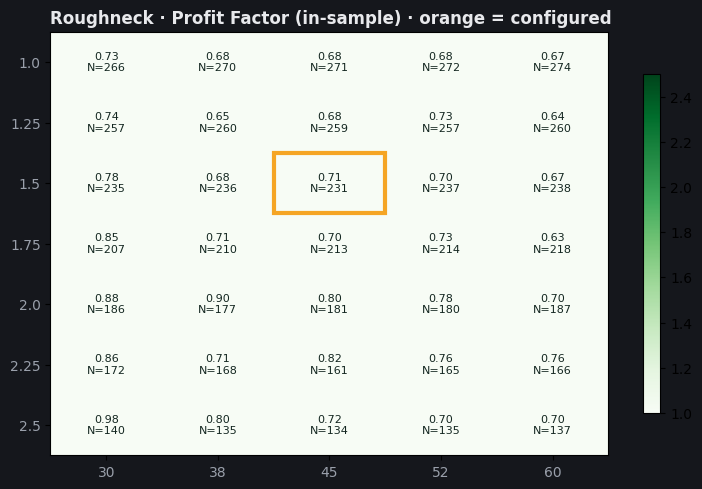

In [8]:
TR = {}   # (mult, atr_len) -> in-sample trades, reused by every later cell

def run_cell(m, L, **kw):
    return eng.run_roughneck_backtest(is_df(m, L), **{**RULES_KW, "long_atr_mult": m, "atr_len": L, **kw})

def evaluate(m, L):
    t = run_cell(m, L)
    TR[(m, L)] = t
    return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))

pf_grid, n_grid = grid_search(evaluate, MULTS, ATR_LENS)
mean_grid = pd.DataFrame({L: {m: summarize(TR[(m, L)])["mean"] for m in MULTS} for L in ATR_LENS})
t_grid    = pd.DataFrame({L: {m: summarize(TR[(m, L)])["t"] for m in MULTS} for L in ATR_LENS})

print("=" * 70)
print("IN-SAMPLE PROFIT FACTOR GRID (rows = long_atr_mult, columns = ATR length)")
print("=" * 70)
display(pf_grid.round(3))
print("\n" + "=" * 70 + "\nIN-SAMPLE TRADE COUNT GRID (N)\n" + "=" * 70)
display(n_grid.astype(int))
print("\n" + "=" * 70 + "\nMEAN NET RETURN PER TRADE, % (100% capital)\n" + "=" * 70)
display(mean_grid.round(3))
print("\n" + "=" * 70 + "\nt-STAT OF THE MEAN\n" + "=" * 70)
display(t_grid.round(2))
plot_grid(pf_grid, n_grid, CHOSEN, title="Roughneck · Profit Factor (in-sample) · orange = configured")

## 3.5 COST-STRESSED GRIDS (x2 AND x3 COSTS)
The same grid with doubled and tripled spread. If the plateau disappears at x2, the edge depends on a tight broker.

In [9]:
stress = {}
for label, mult in (("Costs x2", 2.0), ("Costs x3", 3.0)):
    def ev(m, L, _mult=mult):
        t = run_cell(m, L, cost_bps_per_side=COST_BPS * _mult)
        return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))
    stress[label] = grid_search(ev, MULTS, ATR_LENS)
    print(f"\n{label}: PF grid")
    display(stress[label][0].round(3))
    plst = plateau_check(stress[label][0], stress[label][1], CHOSEN, pf_min=GATE["plateau_pf_min"], n_min=GATE["plateau_n_min"], max_drop_pct=GATE["plateau_max_drop"])
    print(f"{label}: center PF {plst['center_pf']:.3f} | plateau {'YES' if plst['plateau'] else 'NO'} | gate {'PASS' if plst['passed'] else 'FAIL'} | "
          f"cells with PF >= {GATE['plateau_pf_min']}: {plst['pct_cells_pf_ok'] * 100:.0f}%")


Costs x2: PF grid


,30,38,45,52,60
1.00,0.682,0.632,0.635,0.633,0.619
1.25,0.687,0.604,0.628,0.674,0.596
1.50,0.723,0.628,0.659,0.648,0.621
1.75,0.791,0.652,0.653,0.674,0.582
2.00,0.818,0.834,0.745,0.725,0.654
2.25,0.807,0.657,0.768,0.712,0.705
2.50,0.924,0.748,0.674,0.655,0.655


Costs x2: center PF 0.659 | plateau NO | gate FAIL | cells with PF >= 1.3: 0%

Costs x3: PF grid


,30,38,45,52,60
1.00,0.635,0.588,0.591,0.589,0.576
1.25,0.640,0.560,0.584,0.627,0.554
1.50,0.673,0.581,0.612,0.603,0.576
1.75,0.736,0.604,0.606,0.626,0.541
2.00,0.764,0.778,0.694,0.674,0.609
2.25,0.754,0.614,0.718,0.666,0.659
2.50,0.869,0.703,0.632,0.615,0.616


Costs x3: center PF 0.612 | plateau NO | gate FAIL | cells with PF >= 1.3: 0%


In [10]:
import os
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

# ============================ OPCIONES ============================
RENDERER       = None     # None = automático | "vscode" | "notebook_connected" | "iframe"
SHOW_2D_BACKUP = True     # heatmap 2D sin WebGL, siempre se ve
# ==================================================================

if RENDERER:
    pio.renderers.default = RENDERER
elif "VSCODE_PID" in os.environ or "VSCODE_CWD" in os.environ:
    pio.renderers.default = "vscode"

SCENARIOS = [("Base costs", 1.0), ("Costs x2", 2.0), ("Costs x3", 3.0)]
PF_MIN, N_MIN, MAX_DROP = GATE["plateau_pf_min"], GATE["plateau_n_min"], GATE["plateau_max_drop"]


def _plateau(pf, n, m, L):
    """(passed, worst neighbour drop %) if cell (m, L) were the configured one."""
    try:
        r = plateau_check(pf.fillna(0.0), n.fillna(0).astype(int), (m, L),
                          pf_min=PF_MIN, n_min=N_MIN, max_drop_pct=MAX_DROP)
        return bool(r["passed"]), float(r["worst_neighbor_drop_pct"])
    except Exception:
        return False, np.nan


def _f(x, default=np.nan):
    try:
        v = float(x)
        return v if np.isfinite(v) else default
    except Exception:
        return default


# ---- compute every scenario: PF / N / mean / t grids ----
grids = {}
for label, mult in SCENARIOS:
    mk = lambda: pd.DataFrame(index=MULTS, columns=ATR_LENS, dtype=float)
    pf, n, mean, tt = mk(), mk(), mk(), mk()
    for L in ATR_LENS:
        for m in MULTS:
            t = run_cell(m, L, cost_bps_per_side=COST_BPS * mult)
            n.loc[m, L] = len(t)
            if len(t):
                pf.loc[m, L]   = profit_factor(t["pnl"])
                mean.loc[m, L] = float(t["pnl"].mean())
                tt.loc[m, L]   = tstat(t["pnl"])
    pf = pf.astype(float).replace([np.inf, -np.inf], np.nan).where(n > 0)
    grids[label] = dict(pf=pf, n=n.astype(float), mean=mean.astype(float), t=tt.astype(float))
    print(f"{label}: {int(pf.notna().sum().sum())}/{pf.size} celdas con PF finito")

keys = list(grids.keys())
all_pf = np.concatenate([g["pf"].values.ravel() for g in grids.values()])
if not np.isfinite(all_pf).any():
    raise ValueError("Ninguna celda tiene PF finito: revisa run_cell / is_df / RULES_KW antes de graficar.")

XP = list(range(len(ATR_LENS)))                           # posiciones categóricas en x
XT = [str(L) for L in ATR_LENS]
LL = np.tile(np.array(ATR_LENS), (len(MULTS), 1))         # ATR length por celda (hover)
X, Y = np.meshgrid(XP, MULTS)
ib, ia = ATR_LENS.index(CHOSEN[1]), MULTS.index(CHOSEN[0])

# ---- escalas compartidas (a prueba de NaN) ----
z_floor = min(1.0, float(np.nanmin(all_pf))) - 0.35
z_top   = float(np.nanmax(all_pf)) + 0.25
all_mean = np.concatenate([g["mean"].values.ravel() for g in grids.values()])
amax = float(np.nanmax(np.abs(all_mean))) if np.isfinite(all_mean).any() else 0.05
amax = max(0.05, amax)

colorscale = [[0.00, "#b5452f"], [0.25, "#e8a46a"], [0.50, "#f4e79a"], [0.75, "#8fd19e"], [1.00, "#2f7d55"]]
mean_scale = [[0.00, "#b5452f"], [0.45, "#e8704f"], [0.50, "#f5a524"], [0.55, "#8fd19e"], [1.00, "#34d399"]]

TPS = 7                                                   # trazas por escenario
fig, titles, summary = go.Figure(), [], []

for i, key in enumerate(keys):
    g = grids[key]
    pf, n, mean, tt = g["pf"], g["n"], g["mean"], g["t"]
    vis = (i == 0)

    # veredicto de plateau de cada celda (como si fuera la configurada)
    pas  = pd.DataFrame(False, index=pf.index, columns=pf.columns)
    drop = pd.DataFrame(np.nan, index=pf.index, columns=pf.columns)
    for m in MULTS:
        for L in ATR_LENS:
            pas.loc[m, L], drop.loc[m, L] = _plateau(pf, n, m, L)
    has = pf.notna().values
    pas_v = pas.values.astype(bool)
    verdict = np.where(pas_v, "PLATEAU OK", "plateau FAIL")
    n_pass = int((pas_v & has).sum())
    cd = np.dstack([n.values, mean.values, tt.values, drop.values.astype(float)])

    # 1) superficie PF (in-sample)
    fig.add_trace(go.Surface(
        x=XP, y=MULTS, z=pf.values, customdata=cd, text=verdict,
        colorscale=colorscale, cmin=1.0, cmax=2.0,
        colorbar=dict(title="Profit<br>Factor (IS)", len=0.42, y=0.80, x=0.93, thickness=14),
        hovertemplate=("long_atr_mult %{y:g} · ATR index %{x}<br>PF (IS) %{z:.2f}"
                       "<br>Trades (IS) %{customdata[0]:.0f}"
                       "<br>Mean net/trade %{customdata[1]:.2f}% · t %{customdata[2]:.2f}"
                       "<br>Worst neighbour drop %{customdata[3]:.0f}% · %{text}<extra></extra>"),
        visible=vis))

    # 2) piso: mean net % por trade
    fig.add_trace(go.Surface(
        x=XP, y=MULTS, z=np.full(pf.shape, z_floor), surfacecolor=mean.values, customdata=cd, text=verdict,
        colorscale=mean_scale, cmin=-amax, cmax=amax, opacity=0.95,
        colorbar=dict(title="Mean net %<br>per trade", len=0.42, y=0.30, x=0.93, thickness=14),
        lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0),
        hovertemplate=("FLOOR · long_atr_mult %{y:g} · ATR index %{x}"
                       "<br>Mean net/trade %{customdata[1]:+.2f}%"
                       "<br>Trades (IS) %{customdata[0]:.0f}<extra></extra>"),
        visible=vis))

    # 3) marcadores: la celda pasaría / fallaría el gate de plateau
    for mask, name, color, symbol in ((pas_v & has, "Would pass plateau gate", "#34d399", "diamond"),
                                      (~pas_v & has, "Would fail plateau gate", "#f87171", "x")):
        fig.add_trace(go.Scatter3d(
            x=X[mask], y=Y[mask], z=pf.values[mask] + 0.03, mode="markers", name=name, text=LL[mask],
            marker=dict(size=4, color=color, symbol=symbol, line=dict(width=0)),
            hovertemplate=f"{name}<br>mult %{{y:g}} · ATR %{{text}}<extra></extra>",
            showlegend=True, legendgroup=name, visible=vis))

    # 4) líneas verticales de la superficie al piso (celdas que pasarían)
    mk_ = pas_v & has
    xs, ys, zs = [], [], []
    for xv, yv, zv in zip(X[mk_], Y[mk_], pf.values[mk_]):
        xs += [xv, xv, None]; ys += [yv, yv, None]; zs += [zv, z_floor, None]
    fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode="lines",
                               line=dict(color="rgba(52,211,153,0.35)", width=2),
                               hoverinfo="skip", showlegend=False, visible=vis))

    # 5) anillos: vecindad 3x3 de la celda configurada
    rr = range(max(ia - 1, 0), min(ia + 2, len(MULTS)))
    cc = range(max(ib - 1, 0), min(ib + 2, len(ATR_LENS)))
    pts = [(XP[c], MULTS[r], float(pf.iloc[r, c]) + 0.07) for r in rr for c in cc if pd.notna(pf.iloc[r, c])]
    fig.add_trace(go.Scatter3d(
        x=[p[0] for p in pts], y=[p[1] for p in pts], z=[p[2] for p in pts], mode="markers",
        name="3x3 neighbourhood of configured",
        marker=dict(size=8, color="rgba(0,0,0,0)", symbol="circle-open", line=dict(color="#f5a524", width=3)),
        hoverinfo="skip", showlegend=True, legendgroup="nbh", visible=vis))

    # 6) celda configurada
    c_ok   = bool(pas.loc[CHOSEN[0], CHOSEN[1]])
    c_drop = _f(drop.loc[CHOSEN[0], CHOSEN[1]])
    c_pf   = _f(pf.loc[CHOSEN[0], CHOSEN[1]], default=z_floor)
    col = "#34d399" if c_ok else "#f87171"
    fig.add_trace(go.Scatter3d(
        x=[XP[ib]], y=[CHOSEN[0]], z=[c_pf + 0.12], mode="markers+text",
        text=[f"configured {'✓' if c_ok else '✗'}"], textposition="top center",
        textfont=dict(color=col, size=13),
        marker=dict(size=7, color="white", line=dict(color=col, width=3)), showlegend=False,
        hovertemplate=(f"Configured mult {CHOSEN[0]:g}, ATR({CHOSEN[1]})"
                       f"<br>plateau gate: {'PASS' if c_ok else 'FAIL'}<extra></extra>"),
        visible=vis))

    titles.append(f"{cfg['id']} · PF in-sample · {key} · {n_pass}/{int(has.sum())} cells would pass the plateau gate")
    summary.append({"Scenario": key,
                    "PF (IS)": round(_f(pf.loc[CHOSEN[0], CHOSEN[1]]), 3),
                    "N (IS)": int(_f(n.loc[CHOSEN[0], CHOSEN[1]], 0)),
                    "Mean net %": round(_f(mean.loc[CHOSEN[0], CHOSEN[1]]), 3),
                    "t": round(_f(tt.loc[CHOSEN[0], CHOSEN[1]]), 2),
                    "Plateau (configured)": "PASS" if c_ok else "FAIL",
                    "Worst nbr drop %": round(c_drop, 1),
                    "Cells passing plateau": n_pass})

PAD = "\u00a0"
buttons = []
for i, key in enumerate(keys):
    v = [False] * (TPS * len(keys))
    for j in range(TPS):
        v[TPS * i + j] = True
    buttons.append(dict(label=f"{PAD}{key}{PAD}", method="update",
                        args=[{"visible": v}, {"title.text": titles[i]}]))

fig.update_layout(
    template="plotly_dark", paper_bgcolor="#15171c", height=700,
    title=dict(text=titles[0], x=0.02),
    scene=dict(
        xaxis=dict(title="ATR length (bars)", tickmode="array", tickvals=XP, ticktext=XT),
        yaxis_title="long_atr_mult", zaxis_title="Profit Factor", zaxis=dict(range=[z_floor, z_top]),
        aspectmode="manual", aspectratio=dict(x=1.5, y=1.0, z=0.8),
        camera=dict(eye=dict(x=1.6, y=1.6, z=0.9), center=dict(x=0, y=0, z=-0.1))),
    legend=dict(x=0.0, y=0.02, bgcolor="rgba(0,0,0,0)", font=dict(color="#9aa0ab", size=11)),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, xanchor="left", y=1.12, yanchor="top", active=0,
                      buttons=buttons, bgcolor="#9fb3c8", bordercolor="#4a5160", borderwidth=1,
                      pad=dict(l=3, r=3, t=0, b=0), font=dict(color="#15171c", size=12))],
    annotations=[dict(
        text=(f"Height = in-sample PF. Floor = mean net % per trade (green > 0, red < 0). Markers = would the cell pass "
              f"the plateau gate (PF >= {PF_MIN}, N >= {N_MIN}, drop <= {MAX_DROP}% in its 3x3). "
              f"Orange rings = configured cell's neighbourhood."),
        x=0.0, y=-0.02, xref="paper", yref="paper", showarrow=False, xanchor="left",
        font=dict(color="#9aa0ab", size=11))],
    margin=dict(l=0, r=0, t=90, b=30))

# ---- resumen ----
print(f"\nConfigured cell long_atr_mult={CHOSEN[0]:g}, ATR({CHOSEN[1]}) by scenario:")
display(pd.DataFrame(summary).set_index("Scenario"))

# ---- 3D en el notebook (sin escribir archivos) ----
fig.show()

# ---- respaldo 2D (sin WebGL): si esto se ve y el 3D no, el problema es WebGL ----
if SHOW_2D_BACKUP:
    f2 = go.Figure()
    for i, key in enumerate(keys):
        pf, n = grids[key]["pf"], grids[key]["n"]
        txt = [[("" if pd.isna(pf.iloc[r, c]) else f"{pf.iloc[r, c]:.2f}<br>N={int(n.iloc[r, c])}")
                for c in range(len(ATR_LENS))] for r in range(len(MULTS))]
        f2.add_trace(go.Heatmap(
            x=XT, y=[f"{m:g}" for m in MULTS], z=pf.values, text=txt, texttemplate="%{text}",
            colorscale=colorscale, zmin=1.0, zmax=2.0, colorbar=dict(title="PF (IS)"),
            hovertemplate="mult %{y} · ATR %{x}<br>PF %{z:.2f}<extra></extra>", visible=(i == 0)))
    b2 = []
    for i, key in enumerate(keys):
        v = [False] * len(keys); v[i] = True
        b2.append(dict(label=f"{PAD}{key}{PAD}", method="update", args=[{"visible": v}, {"title.text": titles[i]}]))
    f2.update_layout(
        template="plotly_dark", paper_bgcolor="#15171c", height=480, title=dict(text=titles[0], x=0.02),
        xaxis=dict(title="ATR length (bars)", type="category"), yaxis=dict(title="long_atr_mult", type="category"),
        updatemenus=[dict(type="buttons", direction="right", x=0.0, xanchor="left", y=1.18, yanchor="top", active=0,
                          buttons=b2, bgcolor="#9fb3c8", font=dict(color="#15171c", size=12))],
        margin=dict(l=60, r=20, t=100, b=50))
    f2.show()

Base costs: 35/35 celdas con PF finito
Costs x2: 35/35 celdas con PF finito
Costs x3: 35/35 celdas con PF finito

Configured cell long_atr_mult=1.5, ATR(45) by scenario:


,PF (IS),N (IS),Mean net %,t,Plateau (configured),Worst nbr drop %,Cells passing plateau
Scenario,,,,,,,
Base costs,0.710,231,-0.335,-1.55,FAIL,8.2,0
Costs x2,0.659,231,-0.415,-1.92,FAIL,8.3,0
Costs x3,0.612,231,-0.495,-2.29,FAIL,8.4,0


## 4. PLATEAU & ANTI-CLIFF CHECK

In [11]:
pl = plateau_check(pf_grid, n_grid, CHOSEN, pf_min=GATE["plateau_pf_min"], n_min=GATE["plateau_n_min"], max_drop_pct=GATE["plateau_max_drop"])
ia, ib = pf_grid.index.get_loc(CHOSEN[0]), pf_grid.columns.get_loc(CHOSEN[1])
sl = (slice(max(ia - 1, 0), ia + 2), slice(max(ib - 1, 0), ib + 2))
cells = pf_grid.stack()
rank = int((cells > pf_grid.loc[CHOSEN[0], CHOSEN[1]]).sum()) + 1

print("=" * 70)
print(f"3x3 NEIGHBORHOOD OF THE CONFIGURED POINT long_atr_mult={CHOSEN[0]:g}, ATR({CHOSEN[1]})")
print("=" * 70)
print("Profit Factor:"); display(pf_grid.iloc[sl].round(3))
print("N trades:");      display(n_grid.iloc[sl].astype(int))
print(f"Center PF: {pl['center_pf']:.3f} | worst neighbor drop: {pl['worst_neighbor_drop_pct']:.1f}% (max {GATE['plateau_max_drop']}%)")
print(f"Plateau (all 9 cells PF >= {GATE['plateau_pf_min']} and N >= {GATE['plateau_n_min']}): {'YES' if pl['plateau'] else 'NO'}")
print(f"Anti-cliff: {'PASS' if pl['anticliff'] else 'FAIL'} | Gate (plateau AND anti-cliff): {'PASS' if pl['passed'] else 'FAIL'}")
print(f"Cells with PF >= {GATE['plateau_pf_min']}: {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} | cells with mean net > 0: {int((mean_grid.stack() > 0).sum())} of {len(cells)}")
print(f"Configured point ranks #{rank} of {len(cells)} by PF | best cell: {pl['best_cell']} (PF {pl['best_pf']:.3f}) | configured on grid edge: {pl['edge_of_grid']}")

# ---- Secondary diagnostic (NOT the gate): same check on the shorts-excluded (long-only) book ----
def grid_for(**kw):
    def ev(m, L):
        t = run_cell(m, L, **kw)
        return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))
    return grid_search(ev, MULTS, ATR_LENS)
pf_l, n_l = grid_for(side="long")
pl_l = plateau_check(pf_l, n_l, CHOSEN, pf_min=GATE["plateau_pf_min"], n_min=max(3, GATE["plateau_n_min"] // 2), max_drop_pct=GATE["plateau_max_drop"])
print("\n" + "-" * 70)
print(f"DIAGNOSTIC · long side only: center PF {pl_l['center_pf']:.3f} | plateau {'YES' if pl_l['plateau'] else 'NO'} | worst drop {pl_l['worst_neighbor_drop_pct']:.1f}% | gate {'PASS' if pl_l['passed'] else 'FAIL'}")
display(pf_l.round(3))

3x3 NEIGHBORHOOD OF THE CONFIGURED POINT long_atr_mult=1.5, ATR(45)
Profit Factor:


,38,45,52
1.25,0.652,0.677,0.727
1.50,0.679,0.710,0.697
1.75,0.706,0.704,0.726


N trades:


,38,45,52
1.25,260,259,257
1.50,236,231,237
1.75,210,213,214


Center PF: 0.710 | worst neighbor drop: 8.2% (max 30%)
Plateau (all 9 cells PF >= 1.3 and N >= 30): NO
Anti-cliff: PASS | Gate (plateau AND anti-cliff): FAIL
Cells with PF >= 1.3: 0% of 35 | cells with mean net > 0: 0 of 35
Configured point ranks #18 of 35 by PF | best cell: (np.float64(2.5), np.int64(30)) (PF 0.984) | configured on grid edge: False

----------------------------------------------------------------------
DIAGNOSTIC · long side only: center PF 0.805 | plateau NO | worst drop 9.8% | gate FAIL


,30,38,45,52,60
1.00,0.756,0.759,0.751,0.708,0.717
1.25,0.763,0.726,0.747,0.767,0.686
1.50,0.820,0.775,0.805,0.731,0.733
1.75,0.929,0.832,0.806,0.776,0.678
2.00,0.973,1.147,0.975,0.872,0.806
2.25,0.962,0.852,1.038,0.850,0.913
2.50,1.176,1.045,0.897,0.764,0.832


## 4.1 ONE-AT-A-TIME SENSITIVITY OF THE OTHER RULES
The grid above only moves the long trigger. Here each remaining rule is moved alone, around its configured value, with everything else frozen.

In [12]:
IND_SWEEP = set(eng.IND_KEYS)
SWEEPS = {"short_atr_mult": [1.5, 1.75, 2.0, 2.25, 2.5], "stop_dollar": [0.5, 0.75, 1.0, 1.25, 1.5], "trend_min": [0.0, 0.1, 0.25, 0.4, 0.6],
          "long_entry_n": [2, 3, 4, 5, 6], "long_low_n": [5, 6, 8, 10, 12], "lock_level": [0.0, 0.2, 0.4, 0.6, 0.8]}
sweep_rows = []
for k, vals in SWEEPS.items():
    for v in vals:
        if k in IND_SWEEP:
            d = prep(df_raw, **{k: v}); d = d[(d.index >= common_start) & (d.index < OOS_START)]
            t = eng.run_roughneck_backtest(d, **{**RULES, k: v})
        else:
            t = eng.run_roughneck_backtest(d0, **{**RULES, k: v})
        s = summarize(t)
        sweep_rows.append({"rule": k, "value": v, "configured": v == RULES[k], "N": s["n"], "PF": s["pf"], "mean net %": s["mean"], "t": s["t"]})
sweep = pd.DataFrame(sweep_rows)
display(sweep.pivot_table(index="value", columns="rule", values="PF").round(2) if False else sweep.round(3).set_index(["rule", "value"]))
ok_share = sweep.groupby("rule").apply(lambda g: float((g["PF"] >= GATE["plateau_pf_min"]).mean()))
print("Share of tested values per rule with PF >= plateau_pf_min:"); print(ok_share.round(2).to_dict())
fragile = [r for r, s in ok_share.items() if s < 0.6]
print("Fragile rules (< 60% of tested values pass):", fragile if fragile else "none")

configured    N     PF  mean net %      t
rule           value                                           
short_atr_mult 1.50        False  265  0.846      -0.181 -0.772
               1.75        False  257  0.711      -0.345 -1.604
               2.00         True  231  0.710      -0.335 -1.552
               2.25        False  219  0.703      -0.343 -1.538
               2.50        False  207  0.795      -0.221 -0.957
stop_dollar    0.50        False  323  0.543      -0.351 -2.748
               0.75        False  277  0.605      -0.396 -2.371
               1.00         True  231  0.710      -0.335 -1.552
               1.25        False  198  0.801      -0.255 -0.957
               1.50        False  182  1.014       0.019  0.057
trend_min      0.00        False  241  0.673      -0.383 -1.845
               0.10        False  238  0.684      -0.369 -1.757
               0.25         True  231  0.710      -0.335 -1.552
               0.40        False  226  0.733      -0.306 -1.387
               0.60        False  217  0.743      -0.293 -1.303
long_entry_n   2.00        False  245  0.776      -0.256 -1.174
               3.00        False  236  0.804      -0.224 -0.986
               4.00         True  231  0.710      -0.335 -1.552
               5.00        False  224  0.802      -0.230 -0.910
               6.00        False  219  0.823      -0.204 -0.792
long_low_n     5.00        False  186  0.834      -0.190 -0.741
               6.00        False  204  0.761      -0.283 -1.162
               8.00         True  231  0.710      -0.335 -1.552
               10.00       False  249  0.681      -0.372 -1.808
               12.00       False  264  0.712      -0.341 -1.512
lock_level     0.00        False  221  0.754      -0.291 -1.108
               0.20        False  226  0.779      -0.254 -0.989
               0.40         True  231  0.710      -0.335 -1.552
               0.60        False  236  0.719      -0.323 -1.569
               0.80        False  241  0.761      -0.274 -1.346

Share of tested values per rule with PF >= plateau_pf_min:
{'lock_level': 0.0, 'long_entry_n': 0.0, 'long_low_n': 0.0, 'short_atr_mult': 0.0, 'stop_dollar': 0.0, 'trend_min': 0.0}
Fragile rules (< 60% of tested values pass): ['lock_level', 'long_entry_n', 'long_low_n', 'short_atr_mult', 'stop_dollar', 'trend_min']


## 5. DOSE-RESPONSE: DOES A STRONGER TRIGGER MEAN MORE EDGE?

DOSE-RESPONSE AT ATR(45) · in-sample · 100% capital, net of 4 bps/side


,Trades,PF,Mean net %,t-stat,Win %
long_atr_mult,,,,,
1.00,271.0,0.684,-0.374,-1.786,23.985
1.25,259.0,0.677,-0.379,-1.872,24.324
1.50,231.0,0.710,-0.335,-1.552,26.407
1.75,213.0,0.704,-0.345,-1.531,26.761
2.00,181.0,0.800,-0.234,-0.897,27.624
2.25,161.0,0.824,-0.212,-0.752,26.708
2.50,134.0,0.720,-0.373,-1.186,25.373


Spearman (multiple vs mean net return): rho = +0.57 (p = 0.180, only 7 points: descriptive)


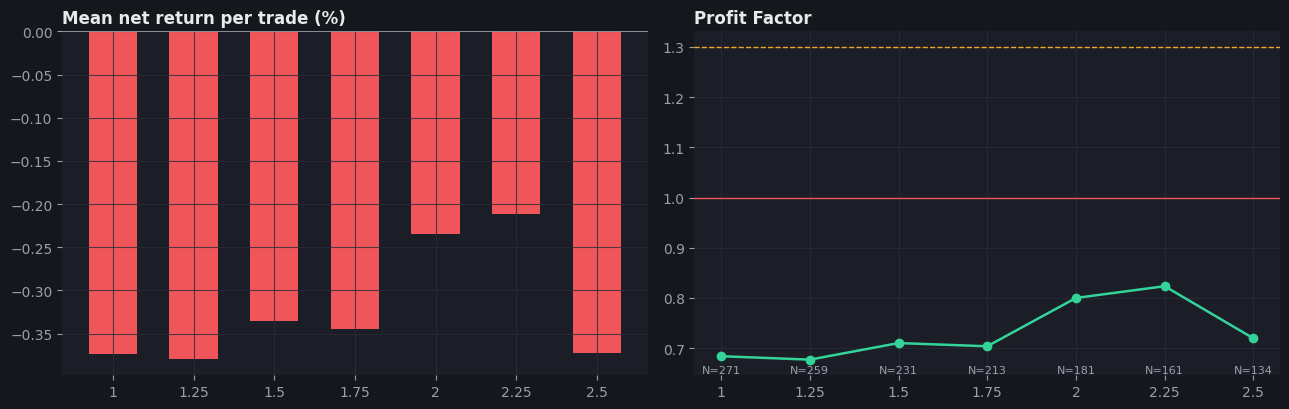

In [13]:
dose = pd.DataFrame({m: summarize(TR[(m, CHOSEN[1])]) for m in MULTS}).T
dose.index.name = "long_atr_mult"
rho_d, p_d = stats.spearmanr(dose.index.to_numpy(float), dose["mean"].to_numpy(float))
print("=" * 70)
print(f"DOSE-RESPONSE AT ATR({CHOSEN[1]}) · in-sample · 100% capital, net of {COST_BPS:g} bps/side")
print("=" * 70)
display(dose.rename(columns={"n": "Trades", "pf": "PF", "mean": "Mean net %", "t": "t-stat", "win": "Win %"}).round(3))
print(f"Spearman (multiple vs mean net return): rho = {rho_d:+.2f} (p = {p_d:.3f}, only {len(dose)} points: descriptive)")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), facecolor=BG)
dark_ax(ax1); dark_ax(ax2)
x = np.arange(len(dose))
ax1.bar(x, dose["mean"], color=[GREEN if v > 0 else RED for v in dose["mean"]], width=0.6); ax1.axhline(0, color=SUB, lw=0.6)
ax1.set_xticks(x); ax1.set_xticklabels([f"{m:g}" for m in dose.index], color=SUB)
ax1.set_title("Mean net return per trade (%)", color=TXT, fontweight="bold", loc="left")
ax2.plot(x, dose["pf"].clip(upper=8), color=GREEN, lw=1.8, marker="o")
ax2.axhline(1.0, color=RED, lw=1.0); ax2.axhline(GATE["plateau_pf_min"], color=ORANGE, ls="--", lw=1.0)
ax2.set_xticks(x); ax2.set_xticklabels([f"{m:g}" for m in dose.index], color=SUB)
ax2.set_title("Profit Factor", color=TXT, fontweight="bold", loc="left")
for i, n in enumerate(dose["n"]):
    ax2.text(i, ax2.get_ylim()[0], f"N={int(n)}", color=SUB, fontsize=8, ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 6. ATR METHOD: SIMPLE AVERAGE VS WILDER (THE NEWSLETTER'S OPEN QUESTION)
The original system probably used Wilder's ATR (TradeStation `AvgTrueRange` is a simple average, `Average True Range` in some platforms is Wilder). Both are tested at the configured length and across the ATR-length grid.

In [14]:
rows = []
for method in ("sma", "wilder"):
    for L in ATR_LENS:
        d = prep(df_raw, atr_len=L, atr_method=method); d = d[(d.index >= common_start) & (d.index < OOS_START)]
        s = summarize(eng.run_roughneck_backtest(d, **{**RULES, "atr_len": L, "atr_method": method}))
        rows.append({"ATR method": method, "ATR length": L, "Trades": s["n"], "PF": s["pf"], "Mean net %": s["mean"], "t": s["t"]})
atr_tbl = pd.DataFrame(rows)
display(atr_tbl.pivot_table(index="ATR length", columns="ATR method", values="PF").round(3))
pf_by_method = atr_tbl.groupby("ATR method")["PF"].median()
print("Median PF across ATR lengths:", pf_by_method.round(3).to_dict())

ATR method,sma,wilder
ATR length,,
30,0.779,0.737
38,0.679,0.703
45,0.710,0.618
52,0.697,0.606
60,0.670,0.606


Median PF across ATR lengths: {'sma': 0.697, 'wilder': 0.618}


## 7. ABLATION BY REGIME (IN-SAMPLE)

In [15]:
combos = {"No trend filter (naked trigger)": dict(trend_mode="off"),
          "No early exit": dict(use_early=False),
          "No ATR tiers": dict(use_tiers=False),
          "No lock at +$1": dict(use_lock=False),
          "Long only": dict(side="long"),
          "Short only": dict(side="short"),
          "All (configured)": dict()}
_is_year_set = set(d0.index.year)
IS_ERAS = [e for e, (a_, b_) in ERAS_ALL.items() if any(a_ <= y <= b_ for y in _is_year_set)]
abl, rows = {}, []
for name, kw in combos.items():
    ind_kw = {k: v for k, v in kw.items() if k in IND_SWEEP}
    d = prep(df_raw, **ind_kw); d = d[(d.index >= common_start) & (d.index < OOS_START)]
    t = eng.run_roughneck_backtest(d, **{**RULES, **kw})
    abl[name] = t
    yr = pd.to_datetime(t["entry_time"]).dt.year
    row = {"Variant": name}
    for e in IS_ERAS:
        a_, b_ = ERAS_ALL[e]
        s = summarize(t[(yr >= a_) & (yr <= b_)])
        row[e] = f"{s['pf']:.2f} | {s['mean']:+.3f}% | {s['n']}" if s["n"] else "n/a"
    s_all = summarize(t)
    row["All in-sample"] = f"{s_all['pf']:.2f} | {s_all['mean']:+.3f}% | {s_all['n']}"
    rows.append(row)
print("=" * 70)
print(f"ABLATION · in-sample · net of {COST_BPS:g} bps/side · PF | mean net % | N")
print("=" * 70)
display(pd.DataFrame(rows).set_index("Variant"))
tc = abl["All (configured)"]
by_year = tc.assign(year=pd.to_datetime(tc["entry_time"]).dt.year).groupby("year")["pnl"].agg(n="size", pf=profit_factor, mean="mean")
print("\nConfigured rules by entry year (in-sample):")
display(by_year.round(3))

ABLATION · in-sample · net of 4 bps/side · PF | mean net % | N


,Pre-COVID (<=2019),COVID (2020),Post-COVID (2021+),All in-sample
Variant,,,,
No trend filter (naked trigger),0.52 | -0.551% | 293,4.82 | +4.869% | 29,0.37 | -0.723% | 101,0.81 | -0.221% | 423
No early exit,0.57 | -0.484% | 146,2.52 | +2.379% | 20,0.25 | -0.837% | 65,0.71 | -0.335% | 231
No ATR tiers,0.04 | -1.385% | 70,n/a,0.01 | -0.958% | 18,0.04 | -1.298% | 88
No lock at +$1,0.68 | -0.433% | 125,4.66 | +7.268% | 14,0.56 | -0.522% | 49,1.09 | +0.117% | 188
Long only,0.58 | -0.435% | 117,4.51 | +3.644% | 15,0.30 | -0.744% | 57,0.80 | -0.204% | 189
Short only,0.52 | -0.679% | 29,0.55 | -1.417% | 5,0.00 | -1.498% | 8,0.44 | -0.923% | 42
All (configured),0.57 | -0.484% | 146,2.52 | +2.379% | 20,0.25 | -0.837% | 65,0.71 | -0.335% | 231



Configured rules by entry year (in-sample):


,n,pf,mean
year,,,
2010,6,0.137,-0.709
2011,27,0.048,-0.853
2012,17,0.101,-0.734
2013,15,0.812,-0.138
2014,16,0.385,-0.705
2015,9,0.424,-1.155
2016,20,0.698,-0.504
2017,9,2.575,1.439
2018,15,0.119,-0.978


## 8. VERDICT & NEXT STEPS

In [16]:
mean_all, mean_naked = summarize(abl["All (configured)"])["mean"], summarize(abl["No trend filter (naked trigger)"])["mean"]
ready = bool(pl["passed"])
print("=" * 80)
print("8. SUMMARY OF IN-SAMPLE PARAMETER STABILITY")
print("=" * 80)
print(f"""
Key Findings:

1. Plateau gate (full in-sample, official): {'PASS' if pl['passed'] else 'FAIL'} - center PF {pl['center_pf']:.3f}, worst neighbor drop {pl['worst_neighbor_drop_pct']:.1f}%,
   plateau {'yes' if pl['plateau'] else 'no'}; {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} cells have PF >= {GATE['plateau_pf_min']}; configured point ranks #{rank} by PF.
   Diagnostic, long side only: {'PASS' if pl_l['passed'] else 'FAIL'} (center PF {pl_l['center_pf']:.3f}).

2. Cost stress: center PF at x2 costs {stress['Costs x2'][0].loc[CHOSEN[0], CHOSEN[1]]:.3f} | at x3 {stress['Costs x3'][0].loc[CHOSEN[0], CHOSEN[1]]:.3f}.

3. Other rules (one at a time): fragile rules = {fragile if fragile else 'none'}.

4. Dose-response: Spearman rho {rho_d:+.2f} between the trigger multiple and mean net return at ATR({CHOSEN[1]}); ATR median PF sma {pf_by_method.get('sma', float('nan')):.2f} vs Wilder {pf_by_method.get('wilder', float('nan')):.2f}.

5. Ablation: configured mean net {mean_all:+.3f}% per trade vs {mean_naked:+.3f}% for the naked trigger without the trend filter (in-sample).

6. Next Step: {'proceed to 03_Roughneck_Robustness_Testing.ipynb with the frozen parameters.' if ready else 'the official gate failed in-sample. Do NOT re-tune the parameters on this result: document it, and carry it to notebook 03 as a documented exception only if the other evidence holds.'}
""")

8. SUMMARY OF IN-SAMPLE PARAMETER STABILITY

Key Findings:

1. Plateau gate (full in-sample, official): FAIL - center PF 0.710, worst neighbor drop 8.2%,
   plateau no; 0% of 35 cells have PF >= 1.3; configured point ranks #18 by PF.
   Diagnostic, long side only: FAIL (center PF 0.805).

2. Cost stress: center PF at x2 costs 0.659 | at x3 0.612.

3. Other rules (one at a time): fragile rules = ['lock_level', 'long_entry_n', 'long_low_n', 'short_atr_mult', 'stop_dollar', 'trend_min'].

4. Dose-response: Spearman rho +0.57 between the trigger multiple and mean net return at ATR(45); ATR median PF sma 0.70 vs Wilder 0.62.

5. Ablation: configured mean net -0.335% per trade vs -0.221% for the naked trigger without the trend filter (in-sample).

6. Next Step: the official gate failed in-sample. Do NOT re-tune the parameters on this result: document it, and carry it to notebook 03 as a documented exception only if the other evidence holds.



## 9. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [17]:
save_json(cfg, "02_optimization.json", {
    "variant": cfg["id"], "ticker": TICKER, "chosen": {"long_atr_mult": CHOSEN[0], "atr_len": CHOSEN[1]},
    "is_window": [str(d0.index.min().date()), str(d0.index.max().date())],
    "plateau": {k: (bool(v) if isinstance(v, (bool, np.bool_)) else (float(v) if isinstance(v, (int, float, np.floating)) else str(v))) for k, v in pl.items()},
    "plateau_n_min_used": int(GATE["plateau_n_min"]),
    "pf_grid": pf_grid.round(4).reset_index().to_dict(orient="records"), "n_grid": n_grid.astype(int).reset_index().to_dict(orient="records"),
    "cost_stress_center_pf": {k: float(v[0].loc[CHOSEN[0], CHOSEN[1]]) for k, v in stress.items()},
    "fragile_rules": fragile, "dose_spearman": {"rho": float(rho_d), "p": float(p_d)},
    "atr_median_pf": {k: float(v) for k, v in pf_by_method.items()},
    "ready_for_03": ready,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_usoil/02_optimization.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/Roughneck_Crude/runs/v1_axi_usoil/02_optimization.json')